### What is Magic Functions?
In Jupyternotebook, the magic functions are pre-defined functions(“magics”).  Using 'magics allows us to executes supplied commands. 

There are two kinds of magics 
1. line-oriented (%)
2. cell-oriented prefaced with % and %% respectively.
https://www.dummies.com/programming/python/common-jupyter-notebook-magic-functions/

!pip install ipython-sql

!pip install --upgrade typing-extensions


In [8]:
import sqlite3 as sql
import pandas as pd

%load_ext sql

Let's begin by creating a database. The following command will create a local instance of our database with the name dataProgramming.db. If you get an error then check:
- That you have run the above code cell and that the libraries are installed and working on your machine.
- That you have the correct permissions on your local machine.


In [9]:
%sql sqlite:///dataProgramming.db

## Create a table

***%%sql*** let you use multiple SQL statements inside a single cell. 

It is now time to create one using a standard SQL command – CREATE TABLE. If the table already existed in the database, an error will pop up. In addition, we set ***PRIMARY KEY*** on USERID to prevent from inserting duplicate writers into the table.

In [10]:
%%sql sqlite://
CREATE TABLE users(
    FirstName VARCHAR(30) NOT NULL,
    LastName VARCHAR(30) NOT NULL,  
    USERID int  NOT NULL UNIQUE, 
    PRIMARY KEY (USERID)
);

(sqlite3.OperationalError) table users already exists
[SQL: CREATE TABLE users(
    FirstName VARCHAR(30) NOT NULL,
    LastName VARCHAR(30) NOT NULL,  
    USERID int  NOT NULL UNIQUE, 
    PRIMARY KEY (USERID)
);]
(Background on this error at: https://sqlalche.me/e/20/e3q8)


# Playing with queries
Let's add some users. To find out more about this command, read [here](https://www.w3schools.com/sql/sql_insert.asp) 

Run this code and then try to add four users of your own. What happens if you do not insert data in the NOT NULL fields?

In [11]:
%%sql sqlite://
INSERT INTO users VALUES ('Ghulam', 'Baker', 1);
INSERT INTO users VALUES ('Savannah', 'Shelton', 2);
# You will get an error if you try to run this more than once as there are UNIQUE requirements for these fields.

(sqlite3.IntegrityError) UNIQUE constraint failed: users.USERID
[SQL: INSERT INTO users VALUES ('Ghulam', 'Baker', 1);]
(Background on this error at: https://sqlalche.me/e/20/gkpj)


### Insert Multiple Values

In [12]:
%%sql Insert Into users (FirstName, LastName, USERID) Values ('Anthony', 'Chia', 3),
('Brian', 'Lee', 4),
('Angel', 'Tan', 5),
('Liam', 'Neckson', 6),
('Henry', 'Park', 7),
('Daniel', 'Boon', 8),
('Hazel', 'Tan', 9),
('Susanna', 'Quek', 10),
('Sylvia', 'Yeoh', 11),
('Britaina', 'Kwok', 12),
('Angeline', 'Zan', 13),
('Lennon', 'Neson',14),
('Harrison', 'WIlliam', 15),
('William', 'Black', 16),
('Bill', 'Clinson', 17),
('Gate', 'Way', 18),
('Cynthia', 'Yeoh', 19)

 * sqlite:///dataProgramming.db
(sqlite3.IntegrityError) UNIQUE constraint failed: users.USERID
[SQL: Insert Into users (FirstName, LastName, USERID) Values ('Anthony', 'Chia' , 3),
('Brian', 'Lee', 4),
('Angel', 'Tan', 5),
('Liam', 'Neckson', 6),
('Henry', 'Park', 7),
('Daniel', 'Boon', 8),
('Hazel', 'Tan', 9),
('Susanna', 'Quek', 10),
('Sylvia', 'Yeoh', 11),
('Britaina', 'Kwok', 12),
('Angeline', 'Zan', 13),
('Lennon', 'Neson',14),
('Harrison', 'WIlliam', 15),
('William', 'Black', 16),
('Bill', 'Clinson', 17),
('Gate', 'Way', 18),
('Cynthia', 'Yeoh', 19)]
(Background on this error at: https://sqlalche.me/e/20/gkpj)


## Our first query

Let's now try to get some data back. Databases are not all about inserting, in fact queries are more useful. Let's grab all of our data. We can do this by using SELECT and signifying * which is a parameter which indicates all of the columns of a table.

In [7]:

%%sql sqlite://
SELECT * from users

Done.


FirstName,LastName,USERID
Ghulam,Baker,1
Savannah,Shelton,2
Anthony,Chia,3
Brian,Lee,4
Angel,Tan,5
Liam,Neckson,6
Henry,Park,7
Daniel,Boon,8
Hazel,Tan,9
Susanna,Quek,10


In [8]:
#one line
%sql SELECT * from users

 * sqlite:///dataProgramming.db
Done.


FirstName,LastName,USERID
Ghulam,Baker,1
Savannah,Shelton,2
Anthony,Chia,3
Brian,Lee,4
Angel,Tan,5
Liam,Neckson,6
Henry,Park,7
Daniel,Boon,8
Hazel,Tan,9
Susanna,Quek,10


In [9]:
## assignment
sqlres = %sql SELECT * from users
sqlres

 * sqlite:///dataProgramming.db
Done.


FirstName,LastName,USERID
Ghulam,Baker,1
Savannah,Shelton,2
Anthony,Chia,3
Brian,Lee,4
Angel,Tan,5
Liam,Neckson,6
Henry,Park,7
Daniel,Boon,8
Hazel,Tan,9
Susanna,Quek,10


What about if we want to select just the names of people in the table? In this case we are not concerned with the USERID. Let's have a look at how we might construct such a query.

In [10]:
sqlres = %sql SELECT FirstName, LastName from users
sqlres

 * sqlite:///dataProgramming.db
Done.


FirstName,LastName
Ghulam,Baker
Savannah,Shelton
Anthony,Chia
Brian,Lee
Angel,Tan
Liam,Neckson
Henry,Park
Daniel,Boon
Hazel,Tan
Susanna,Quek


In [11]:
''' 
What about if we want to query specific things based on more complex logic? 
Look up Savannah's user ID and put it between the apostrophes in the USERID=''
'''

%sql SELECT FirstName FROM users WHERE USERID='2'

 * sqlite:///dataProgramming.db
Done.


FirstName
Savannah


### 1. TRY YOURSELF (2 minutes)


In [ ]:
''' 
What about if we want to query specific things based on more complex logic? 
Look up Savannah's user ID and put it between the apostrophes in the USERID=''
'''

%sql SELECT FirstName FROM users WHERE USERID='Savannah_user_id'

In [ ]:
# We can even do mathematical operations inline, for instance we could use the mod function (%) 
# and look for even fields (divisible by 2 where the integer remainder = 0 ie no remainder.)
%sql SELECT USERID FROM users WHERE FirstName='Savannah' and USERID %2 = 0

### 2. Try yourself:

#### find how many people with Surname 'Tan' (2 minutes)

### 3. TRY YOURSELF
*** FIND persons whose name start with S  e.g., Savannah, Susanna, Sylvia

See https://www.w3schools.com/sql/sql_like.asp

In [ ]:
%sql Select * from users where _____ LIKE 'S%'

## Can we rename the table headings from the data we get back from our query? See if you can figure this out using AS

[The AS command](https://www.w3schools.com/sql/sql_ref_as.asp)

### 4. TRY Using AS

In [51]:
# SELECT something AS something FROM somewhere;


Has the AS command changed the initial data from the table? Run a query on the table to see if it has changed.

In [52]:
# SELECT something AS something FROM somewhere;
%sql SELECT FirstName as [First Name], LastName as [Last Name] from users

 * sqlite:///dataProgramming.db
Done.


First Name,Last Name
Ghulam,Baker
Savannah,Shelton
Anthony,Chia
Brian,Lee
Angel,Tan
Liam,Neckson
Henry,Park
Daniel,Boon
Hazel,Tan
Susanna,Quek


We saw the '*' parameter earlier, where we pull all of our data back. In some cases these sorts of queries can be really inefficient (and expensive!). When our queries bring back all rows and all columns for
a table, it can be really inefficient (and expensive!).  

One way that we can overcome this is by limiting the number of rows we return. 

We can limit the number of rows returned using the LIMIT modifier to our select statement:

In [31]:
%sql SELECT * From users LIMIT 1

 * sqlite:///dataProgramming.db
Done.


FirstName,LastName,USERID
Ghulam,Baker,1


In [33]:

%sql Select * from users Order BY LastName ASC

 * sqlite:///dataProgramming.db
Done.


FirstName,LastName,USERID
Ghulam,Baker,1
William,Black,16
Daniel,Boon,8
Anthony,Chia,3
Bill,Clinson,17
Britaina,Kwok,12
Brian,Lee,4
Liam,Neckson,6
Lennon,Neson,14
Henry,Park,7


In [34]:

%sql Select * from users Order BY LastName DESC

 * sqlite:///dataProgramming.db
Done.


FirstName,LastName,USERID
Angeline,Zan,13
Sylvia,Yeoh,11
Cynthia,Yeoh,19
Gate,Way,18
Harrison,WIlliam,15
Angel,Tan,5
Hazel,Tan,9
Savannah,Shelton,2
Susanna,Quek,10
Henry,Park,7


### 5. Try sorting using First Name

In [39]:
%sql sqlite:///dataProgramming.db
%sql Select * from users Order BY FirstName

 * sqlite:///dataProgramming.db
Done.


FirstName,LastName,USERID
Angel,Tan,5
Angeline,Zan,13
Anthony,Chia,3
Bill,Clinson,17
Brian,Lee,4
Britaina,Kwok,12
Cynthia,Yeoh,19
Daniel,Boon,8
Gate,Way,18
Ghulam,Baker,1


## The use of aggregate functions. Can we count the number of users with the same surname? 

[Aggregate functions](https://www.w3resource.com/sql/aggregate-functions/aggregate-function.php)


An aggregate function performs a calculation on one or multiple values (rows) and returns a single value as a result.
We can then use an aggregate function to group our users by their "LastName" and COUNT how many have the same surname.

First of all, add two entries to the users table with identiacal surnames:

### Try 6. Insert

In [ ]:
%%sql sqlite://
INSERT INTO users VALUES (---, ---,---);
INSERT INTO users VALUES (---, ---,---);


If we use the [COUNT and GROUP BY](https://www.w3resource.com/sql/aggregate-functions/count-with-group-by.php) aggregate functions, we can find out how many users have the same surname:



In [40]:
%sql SELECT LastName, COUNT(*) as Entries from users GROUP BY Lastname;

 * sqlite:///dataProgramming.db
Done.


LastName,Entries
Baker,1
Black,1
Boon,1
Chia,1
Clinson,1
Kwok,1
Lee,1
Neckson,1
Neson,1
Park,1


Can you combine the above aggregate function and only LIMIT the query to show the first three rows?

Try adding an ORDER by parameter to the previous query to further refine our output.
You can find some documentation [here](https://www.w3schools.com/sql/sql_ref_order_by.asp)
HINT: Order first!

In [35]:
# We might even want to get smallest/largest values as follows
%sql SELECT min(USERID), max(USERID) from users

 * sqlite:///dataProgramming.db
Done.


min(USERID),max(USERID)
1,19


Now see if you can stretch your legs a bit. Experiment with queries using some or all of the following operators.

- 'AND' 
- 'OR'
- 'NOT' 
- 'IN'
- '<>' 
- '!='
- '>=' 
- '>' 
- '<' 
- '<='

Some examples of syntax for each of these parameters can be found [here](https://www.w3schools.com/sql/default.asp). The logic is somewhat similar to the logic you would use in Python.

### Try 7

Get the table as below using what you have learned.  LIKE FIRSTNAME OR LIKE LASTNAME
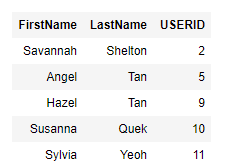

### Try 8

Get the table as below using 'AND'
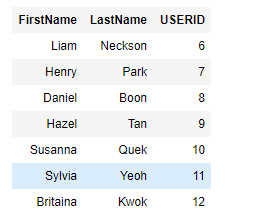

In [1]:
%load_ext sql
%sql sqlite:///data/oulad.db3

## Now it's time to start working with tables and CSV files in unison. There are a few steps to this process, so go slowly and try to understand what each code block is doing.
We are going to drop any existing tables. We could institute this logic also in our create table. You might sometimes see this as
`CREATE TABLE IF NOT EXISTS`
For this exercise we will be efficient and clean up after ourselves!


note:
unison" is used to emphasize the coordination or synchronization between working with tables and CSV files. It suggests that these two elements, tables (likely referring to database tables) and CSV files, are being addressed or manipulated in a harmonious and coordinated manner. The instructions encourage a deliberate and careful approach to comprehend each step in the code blocks, indicating a step-by-step process for working with these data structures together

In [2]:
%%sql 
select * from sqlite_master where type='table'

 * sqlite:///data/oulad.db3
Done.


type,name,tbl_name,rootpage,sql
table,courses,courses,5,"CREATE TABLE courses( code_module TEXT, code_presentation TEXT, module_presentation_length INTEGER)"


In [3]:
%%sql
DROP TABLE assessments

 * sqlite:///data/oulad.db3
(sqlite3.OperationalError) no such table: assessments
[SQL: DROP TABLE assessments]
(Background on this error at: https://sqlalche.me/e/20/e3q8)


In [13]:
%%sql 
select * from sqlite_master where type='table'

 * sqlite:///data/oulad.db3
Done.


type,name,tbl_name,rootpage,sql
table,courses,courses,5,"CREATE TABLE courses( code_module TEXT, code_presentation TEXT, module_presentation_length INTEGER)"
table,assessments,assessments,2,"CREATE TABLE assessments( code_module TEXT, code_presentation TEXT, id_assessment INTEGER, assessment_type TEXT, date INT, weight INT)"


## We first need to create our structure for the table. 
You can look at the CSV file (or just the headings) to get a sense of the data. These data types will be given to you for this first exercise, but you will have to create the structures for the other tables yourself.

In [14]:
%%sql sqlite://
    CREATE TABLE assessments(
    code_module TEXT,
    code_presentation TEXT,
    id_assessment INTEGER,
    assessment_type TEXT,
    date INT,
    weight INT
);

(sqlite3.OperationalError) table assessments already exists
[SQL: CREATE TABLE assessments(
    code_module TEXT,
    code_presentation TEXT,
    id_assessment INTEGER,
    assessment_type TEXT,
    date INT,
    weight INT
);]
(Background on this error at: https://sqlalche.me/e/20/e3q8)


In [20]:
%%sql sqlite://
    select * from assessments;

Done.


code_module,code_presentation,id_assessment,assessment_type,date,weight
AAA,2013J,1752,TMA,19,10
AAA,2013J,1753,TMA,54,20
AAA,2013J,1754,TMA,117,20
AAA,2013J,1755,TMA,166,20
AAA,2013J,1756,TMA,215,30
AAA,2013J,1757,Exam,DEFAULT,100
AAA,2014J,1758,TMA,19,10
AAA,2014J,1759,TMA,54,20
AAA,2014J,1760,TMA,117,20
AAA,2014J,1761,TMA,166,20


In [18]:
# let's empty our tables first, incase we already have values there.
%sql DELETE FROM assessments;

 * sqlite:///data/oulad.db3
0 rows affected.


[]

## Now the next cell might look a little intimidating, but don't panic just yet!

We are using a couple of external libraries to help us. OS to handle the path and file that we are interacting with and CSV to deal with the structure of our comma separated values.

Our aim here is to iterate through these values in order to populate the table structure that we just created with data.

Our for loop performs some checks so as not to produce invalid data types or 'null' data.

I have also left a bit of an inefficient solution to the problem with 6 fields defined as variables. Can you optimise this bit of code? Hint: it's more iteration!

Finally, this code block inserts the corresponding values from our assessments.csv into our assessments table. We have gone from CSV to Python, to SQL. Our final step is to close our CSV reader!

In [19]:
import os
import csv 

fin    = open(os.path.join("data","assessments.csv"), "rt") # you might need to change rt (read text)/rb (read binary) to match representations
csv_in = csv.reader(fin)
next(csv_in);
for line  in csv_in:
    # Empty, non-string values in the CSV should be changed to the SQL Keyword DEFAULT
    if line[2] == "": 
        line[2] = "DEFAULT"
    if line[4] == "": 
        line[4] = "DEFAULT"
    if line[5] == "": 
        line[5] = "DEFAULT"
    # We will do this verbose so that you can see how each variable is passed. You will want to optimise this, however.
    field1 = line[0]
    field2 = line[1]
    field3 = line[2]
    field4 = line[3]
    field5 = line[4]
    field6 = line[5]
    %sql INSERT INTO assessments (code_module, code_presentation, id_assessment, assessment_type, date, weight) VALUES (:field1, :field2, :field3, :field4, :field5, :field6);
fin.close()

 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:

1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.
 * sqlite:///data/oulad.db3
1 rows affected.


## Let's do a final check
We will query the table to ensure that we have some data. Check this against your CSV file and see if it matches. Are the data types valid for this representation?

In [21]:

sqlres = %sql SELECT * from assessments;
sqlres


 * sqlite:///data/oulad.db3
Done.


code_module,code_presentation,id_assessment,assessment_type,date,weight
AAA,2013J,1752,TMA,19,10
AAA,2013J,1753,TMA,54,20
AAA,2013J,1754,TMA,117,20
AAA,2013J,1755,TMA,166,20
AAA,2013J,1756,TMA,215,30
AAA,2013J,1757,Exam,DEFAULT,100
AAA,2014J,1758,TMA,19,10
AAA,2014J,1759,TMA,54,20
AAA,2014J,1760,TMA,117,20
AAA,2014J,1761,TMA,166,20


### Let's peek (new)


In [22]:
allrows =  %sql select * from assessments

 * sqlite:///data/oulad.db3
Done.


In [23]:
type(allrows)

sql.run.ResultSet

In [24]:
allrows.field_names

['code_module',
 'code_presentation',
 'id_assessment',
 'assessment_type',
 'date',
 'weight']

In [25]:
%sql sqlite:///alldatabases.db

In [26]:
%%sql 
select * from sqlite_master where type='table'

 * sqlite:///alldatabases.db
   sqlite:///data/oulad.db3
Done.


type,name,tbl_name,rootpage,sql


## We have reached the end of the demonstration section. Now it's your turn!
See if you can create the structure for the other tables and populate the tables with the values from the CSV files using Python. Be warned, not all data types are obvious! We have some boolean types, some date representations and other challenging data types to map.

If you find this easy then feel free to go ahead and try to take the exercise further. For example you could:
- Produce summary statistics for the columns using COUNT, AVG, SUM etc.
- Create some small visualisations of the data. We cover plotting later on in the course, so this might be a nice precursor to exploring tools like Matplotlib.
- If you really want to explore more deeply you might want to look at some advanced SQL functions, for instance by  combining multiple queries using JOINS or UNIONS.

In [27]:
%%sql sqlite://
    CREATE TABLE courses(
    code_module TEXT,
    code_presentation TEXT,
    module_presentation_length INTEGER
);

(sqlite3.OperationalError) table courses already exists
[SQL: CREATE TABLE courses(
    code_module TEXT,
    code_presentation TEXT,
    module_presentation_length INTEGER
);]
(Background on this error at: https://sqlalche.me/e/20/e3q8)


In [28]:
# Let's get coding!
fin    = open(os.path.join("data","courses.csv"), "rt")
csv_in = csv.reader(fin)

In [29]:
next(csv_in);
for line  in csv_in:
    # Empty, non-string values in the CSV should be changed to the SQL Keyword DEFAULT
    if line[0] == "": line[0] = "DEFAULT"
    if line[1] == "": line[1] = "DEFAULT"
    if line[2] == "": line[2] = "DEFAULT"
    # We will do this verbose so that you can see how each variable is passed. You will want to optimise this, however.
    field1 = line[0]
    field2 = line[1]
    field3 = line[2]
    %sql INSERT INTO courses (code_module, code_presentation, module_presentation_length) VALUES (:field1, :field2, :field3);
fin.close()

   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
1 rows affected.
   sqlite:///alldatabases.db
 * sqlite

In [30]:
%sql select * from courses

   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
Done.


code_module,code_presentation,module_presentation_length
AAA,2013J,268
AAA,2014J,269
BBB,2013J,268
BBB,2014J,262
BBB,2013B,240
BBB,2014B,234
CCC,2014J,269
CCC,2014B,241
DDD,2013J,261
DDD,2014J,262


In [32]:
%sql SELECT  code_module, AVG(module_presentation_length) as [Average Presentation Length] from courses GROUP BY code_module;

   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
Done.


code_module,Average Presentation Length
AAA,268.5
BBB,251.0
CCC,255.0
DDD,251.0
EEE,259.3333333333333
FFF,254.5
GGG,257.0


In [33]:
a=%sql SELECT  code_module, AVG(module_presentation_length) as [Average Presentation Length] from courses GROUP BY code_module;

   sqlite:///alldatabases.db
 * sqlite:///data/oulad.db3
Done.


In [34]:
import pandas as pd

In [35]:
b=pd.DataFrame(a)

In [36]:
b

,code_module,Average Presentation Length
0,AAA,268.500000
1,BBB,251.000000
2,CCC,255.000000
3,DDD,251.000000
4,EEE,259.333333
5,FFF,254.500000
6,GGG,257.000000


<Axes: xlabel='code_module'>

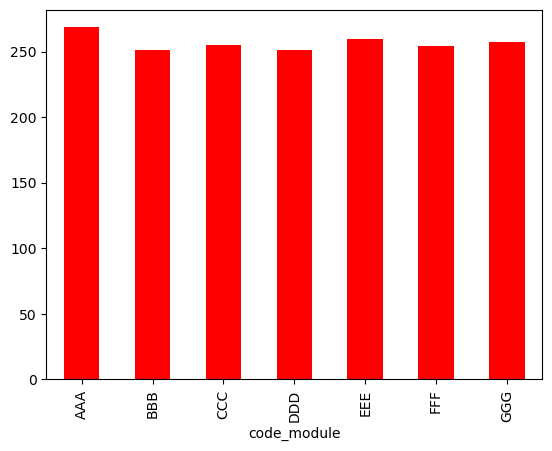

In [37]:
b.plot.bar(x=0,y=1, legend=0, color='red')

In [35]:
fin    = open(os.path.join("data","studentAssessment.csv"), "rt")
csv_in = csv.reader(fin)

In [36]:
fin    = open(os.path.join("data","studentInfo.csv"), "rt")
csv_in = csv.reader(fin)

In [37]:
fin    = open(os.path.join("data","studentRegistration.csv"), "rt")
csv_in = csv.reader(fin)

In [38]:
fin    = open(os.path.join("data","vle.csv"), "rt")
csv_in = csv.reader(fin)

# Possible Answers:

### Try 1

In [41]:
%sql SELECT FirstName FROM users WHERE USERID='2'

 * sqlite:///dataProgramming.db
Done.


FirstName
Savannah


### Try 2

In [44]:
%sql select * from users where LastName = 'Tan';

 * sqlite:///dataProgramming.db
Done.


FirstName,LastName,USERID
Angel,Tan,5
Hazel,Tan,9


### Try 3
*** FIND persons whose name start with S  e.g., Savannah, Susanna, Sylvia

See https://www.w3schools.com/sql/sql_like.asp

In [45]:
%sql Select * from users where FirstName LIKE 'S%'

 * sqlite:///dataProgramming.db
Done.


FirstName,LastName,USERID
Savannah,Shelton,2
Susanna,Quek,10
Sylvia,Yeoh,11


### Try 4

In [46]:
%sql SELECT FirstName as 'First Name', LastName as 'Last Name' from users

 * sqlite:///dataProgramming.db
Done.


First Name,Last Name
Ghulam,Baker
Savannah,Shelton
Anthony,Chia
Brian,Lee
Angel,Tan
Liam,Neckson
Henry,Park
Daniel,Boon
Hazel,Tan
Susanna,Quek


### Try 5
Try sorting using First Na

In [48]:

%sql Select * from users Order BY FirstName

 * sqlite:///dataProgramming.db
Done.


FirstName,LastName,USERID
Angel,Tan,5
Angeline,Zan,13
Anthony,Chia,3
Bill,Clinson,17
Brian,Lee,4
Britaina,Kwok,12
Cynthia,Yeoh,19
Daniel,Boon,8
Gate,Way,18
Ghulam,Baker,1


### Try 6

In [ ]:
%%sql sqlite://
INSERT INTO users VALUES (---, ---,---);
INSERT INTO users VALUES (---, ---,---);


### Try 7

In [50]:
%sql select * from users where FirstName Like 'S%' OR LastName Like 'T%'

 * sqlite:///dataProgramming.db
Done.


FirstName,LastName,USERID
Savannah,Shelton,2
Angel,Tan,5
Hazel,Tan,9
Susanna,Quek,10
Sylvia,Yeoh,11


### Try 8

In [49]:
%sql select * from users where USERID > 5 AND USERID < 13

 * sqlite:///dataProgramming.db
Done.


FirstName,LastName,USERID
Liam,Neckson,6
Henry,Park,7
Daniel,Boon,8
Hazel,Tan,9
Susanna,Quek,10
Sylvia,Yeoh,11
Britaina,Kwok,12
